In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [70]:
df = pd.read_csv('data.csv')
df

,User_ID,Profile,Date,Steps,Sleep_Hours,Resting_HR,HRV,Fatigue_Score,Fatigue_State
0,User_1,Desk Worker,2025-08-01,3381.0,6.083696,74.569334,50.705167,0.000000,Optimal
1,User_1,Desk Worker,2025-08-02,9132.0,8.465187,70.235605,54.583534,0.000000,Optimal
2,User_1,Desk Worker,2025-08-03,7566.0,9.288012,73.914258,40.879240,1.000000,Optimal
3,User_1,Desk Worker,2025-08-04,3125.0,5.368651,73.309647,46.400229,2.500000,Strained
4,User_1,Desk Worker,2025-08-05,3976.0,5.582638,65.490709,37.750058,4.250000,Burnout
...,...,...,...,...,...,...,...,...,...
8995,User_50,Athlete,2026-01-23,17507.0,7.044478,59.403398,79.504667,1.500619,Optimal
8996,User_50,Athlete,2026-01-24,16792.0,7.400648,46.544443,87.954971,1.750309,Optimal
8997,User_50,Athlete,2026-01-25,2900.0,8.701837,50.047920,59.427423,0.875155,Optimal
8998,User_50,Athlete,2026-01-26,14922.0,7.039033,57.585249,63.175107,0.437577,Optimal


In [71]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   User_ID        9000 non-null   str    
 1   Profile        9000 non-null   str    
 2   Date           9000 non-null   str    
 3   Steps          8280 non-null   float64
 4   Sleep_Hours    9000 non-null   float64
 5   Resting_HR     8284 non-null   float64
 6   HRV            8280 non-null   float64
 7   Fatigue_Score  9000 non-null   float64
 8   Fatigue_State  9000 non-null   str    
dtypes: float64(5), str(4)
memory usage: 932.9 KB


In [72]:
df['Date'] = pd.to_datetime(df['Date'])
df['Day_of_week'] = df['Date'].dt.day_name()

In [73]:
df.head()

,User_ID,Profile,Date,Steps,Sleep_Hours,Resting_HR,HRV,Fatigue_Score,Fatigue_State,Day_of_week
0,User_1,Desk Worker,2025-08-01,3381.0,6.083696,74.569334,50.705167,0.00,Optimal,Friday
1,User_1,Desk Worker,2025-08-02,9132.0,8.465187,70.235605,54.583534,0.00,Optimal,Saturday
2,User_1,Desk Worker,2025-08-03,7566.0,9.288012,73.914258,40.879240,1.00,Optimal,Sunday
3,User_1,Desk Worker,2025-08-04,3125.0,5.368651,73.309647,46.400229,2.50,Strained,Monday
4,User_1,Desk Worker,2025-08-05,3976.0,5.582638,65.490709,37.750058,4.25,Burnout,Tuesday


In [74]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   User_ID        9000 non-null   str           
 1   Profile        9000 non-null   str           
 2   Date           9000 non-null   datetime64[us]
 3   Steps          8280 non-null   float64       
 4   Sleep_Hours    9000 non-null   float64       
 5   Resting_HR     8284 non-null   float64       
 6   HRV            8280 non-null   float64       
 7   Fatigue_Score  9000 non-null   float64       
 8   Fatigue_State  9000 non-null   str           
 9   Day_of_week    9000 non-null   str           
dtypes: datetime64[us](1), float64(5), str(4)
memory usage: 978.0 KB


In [75]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

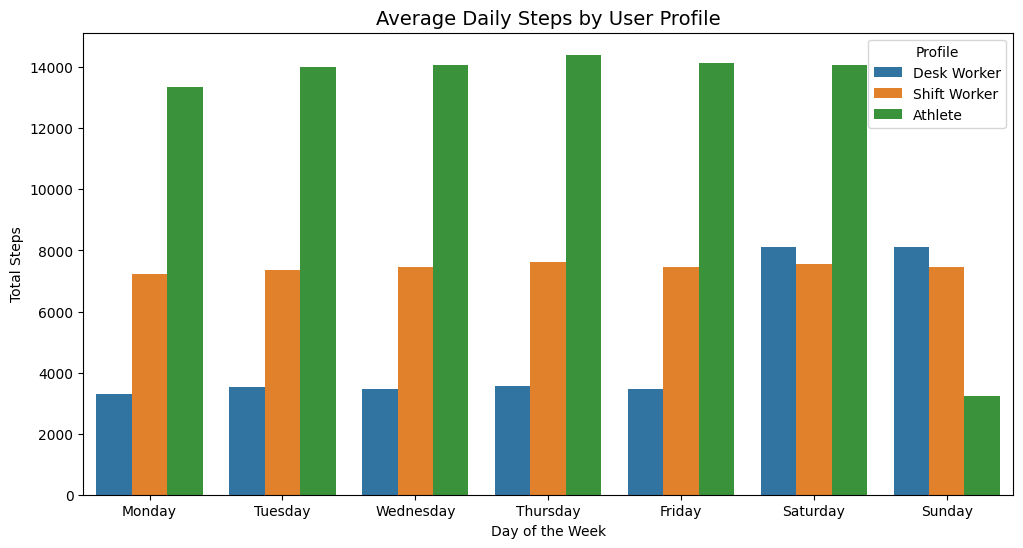

In [76]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Day_of_week', y='Steps', hue='Profile',order=days_order, errorbar=None)
plt.title("Average Daily Steps by User Profile", fontsize=14)
plt.ylabel("Total Steps")
plt.xlabel("Day of the Week")
plt.show()

In [77]:
df.isnull().sum()

User_ID            0
Profile            0
Date               0
Steps            720
Sleep_Hours        0
Resting_HR       716
HRV              720
Fatigue_Score      0
Fatigue_State      0
Day_of_week        0
dtype: int64

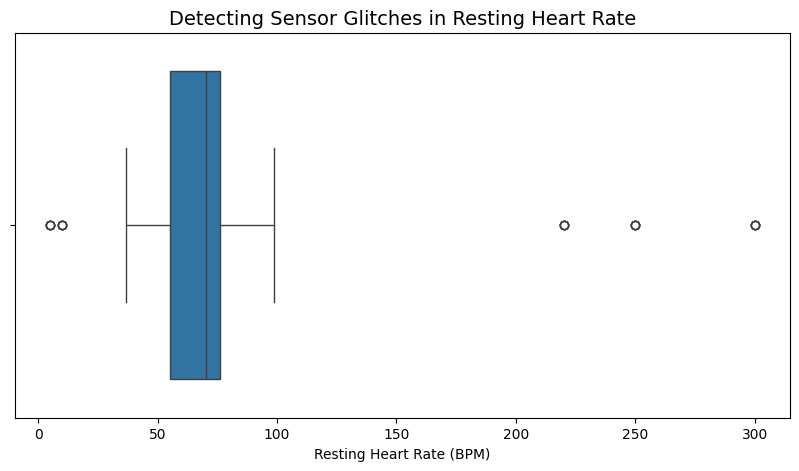

In [78]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['Resting_HR'])
plt.title("Detecting Sensor Glitches in Resting Heart Rate", fontsize=14)
plt.xlabel("Resting Heart Rate (BPM)")
plt.show()

In [79]:
df.loc[df['Resting_HR'] > 100, 'Resting_HR'] = df['Resting_HR'].median()

In [80]:
df = df.sort_values(by=['User_ID', 'Date'])

df['Steps'] = df.groupby('User_ID')['Steps'].transform(lambda x: x.interpolate(method='linear').bfill())
df['Resting_HR'] = df.groupby('User_ID')['Resting_HR'].transform(lambda x: x.interpolate(method='linear').bfill())
df['HRV'] = df.groupby('User_ID')['HRV'].transform(lambda x: x.interpolate(method='linear').bfill())

In [81]:
df.isnull().sum()

User_ID          0
Profile          0
Date             0
Steps            0
Sleep_Hours      0
Resting_HR       0
HRV              0
Fatigue_Score    0
Fatigue_State    0
Day_of_week      0
dtype: int64

In [82]:
df['3_Day_Avg_Sleep'] = df.groupby('User_ID')['Sleep_Hours'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
df['3_Day_Avg_HRV'] = df.groupby('User_ID')['HRV'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
df['3_Day_Avg_Steps'] = df.groupby('User_ID')['Steps'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())

In [83]:
df.head()

,User_ID,Profile,Date,Steps,Sleep_Hours,Resting_HR,HRV,Fatigue_Score,Fatigue_State,Day_of_week,3_Day_Avg_Sleep,3_Day_Avg_HRV,3_Day_Avg_Steps
0,User_1,Desk Worker,2025-08-01,3381.0,6.083696,74.569334,50.705167,0.00,Optimal,Friday,6.083696,50.705167,3381.000000
1,User_1,Desk Worker,2025-08-02,9132.0,8.465187,70.235605,54.583534,0.00,Optimal,Saturday,7.274442,52.644351,6256.500000
2,User_1,Desk Worker,2025-08-03,7566.0,9.288012,73.914258,40.879240,1.00,Optimal,Sunday,7.945632,48.722647,6693.000000
3,User_1,Desk Worker,2025-08-04,3125.0,5.368651,73.309647,46.400229,2.50,Strained,Monday,7.707283,47.287668,6607.666667
4,User_1,Desk Worker,2025-08-05,3976.0,5.582638,65.490709,37.750058,4.25,Burnout,Tuesday,6.746433,41.676509,4889.000000


In [84]:
df = pd.get_dummies(df, columns=['Profile'], dtype=int)

In [85]:
feature_to_drop = ['User_ID', 'Date', 'Day_of_week', 'Fatigue_Score']
final_df = df.drop(columns=feature_to_drop)

In [86]:
final_df.head()

,Steps,Sleep_Hours,Resting_HR,HRV,Fatigue_State,3_Day_Avg_Sleep,3_Day_Avg_HRV,3_Day_Avg_Steps,Profile_Athlete,Profile_Desk Worker,Profile_Shift Worker
0,3381.0,6.083696,74.569334,50.705167,Optimal,6.083696,50.705167,3381.000000,0,1,0
1,9132.0,8.465187,70.235605,54.583534,Optimal,7.274442,52.644351,6256.500000,0,1,0
2,7566.0,9.288012,73.914258,40.879240,Optimal,7.945632,48.722647,6693.000000,0,1,0
3,3125.0,5.368651,73.309647,46.400229,Strained,7.707283,47.287668,6607.666667,0,1,0
4,3976.0,5.582638,65.490709,37.750058,Burnout,6.746433,41.676509,4889.000000,0,1,0


In [87]:
final_df.to_csv("model_ready_telemetry.csv", index=False)

In [88]:
print(df['Fatigue_State'].value_counts())

Fatigue_State
Optimal     5498
Strained    2785
Burnout      717
Name: count, dtype: int64
